# Milestone 1: Affordable Housing and Parking Meters in NYC

## Team and individual contributions

| Member | Student ID | Research questions and charts | Data cleaning | Integration | Website part |
|---|---|---|---|---|---|
| Ahmed Sayed | 16008533 | Q1, Q2 | Housing dataset: missing values and duplicates | Aggregation of housing data | Dropdown filters |
| Mohannad Hany | 16008825 | Q3, Q4 | Transport dataset: missing values and duplicates | Aggregation of transport data | Search mode |
| Abdelrahman Mohamed | 16001205 | Q5, Q6 | Housing dataset: outliers (IQR + domain rules) | Merge and join-key justification | Generate Report callback |
| Mohamed Wael | 16003528 | Q7, Q8 | Transport dataset: outliers (domain rules) | Post-integration cleaning | Charts layout and styling |
| Kareem Alguineedy | 16007546 | Q9, Q10 | Standardizing dates, ZIPs and boroughs (both datasets) | EDA of the integrated data | Story section |
| Deema Seada | 16002455 | Q11, Q12 | Inconsistent categories and string cleaning | Feasibility check and notebook Markdown | Deployment, README, final testing |

## Datasets

- **Housing:** Affordable Housing Production by Building (HPD), dataset ID `hg8x-zxpr`  
  https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr
- **Transportation:** Parking Meters Locations & Status (DOT), dataset ID `693u-uax6`  
  https://data.cityofnewyork.us/Transportation/Parking-Meters-Locations-and-Status/693u-uax6

## Main research idea

Affordable housing production and parking-meter locations do not share a direct record-level key. The housing dataset includes building coordinates and community-board information, while the meter dataset includes meter coordinates but no matching housing project ID, ZIP code, community board, or project date. We therefore use geographic proximity: a grid-based neighborhood window is used to count active meters around each housing record and housing records around each meter. The resulting record-level measures are then summarized by borough, community board, and housing completion year.

The analysis is descriptive. It can identify spatial patterns and associations, but it cannot establish that parking meters cause housing development or that housing development causes changes in parking-meter availability.

## Research questions

1. How many active parking meters are there per 1,000 affordable housing units in each borough?
2. What share of affordable housing records are near an active meter, by building completion year?
3. How does nearby active-meter availability differ between new construction and preservation?
4. Is the share of three-bedroom-or-larger units associated with the number of nearby active meters?
5. How does the income-band composition of affordable housing relate to nearby active-meter counts?
6. Which community boards have more newly constructed affordable units, and how does nearby active-meter availability compare?
7. How do affordable housing locations and active parking-meter locations overlap geographically?
8. Are inactive meters more or less common near new affordable housing than elsewhere?
9. Are larger affordable housing records associated with more nearby active meters?
10. How do meter time-limit categories differ between meters near affordable housing and meters farther away?
11. Is the affordable-unit share of a building associated with nearby active-meter counts?
12. Does project duration differ between affordable housing records near an active meter and those without one?

## Prompts used

AI assistance (Claude) was used as a starting point for the plan, the code structure and the wording of some cells. The team ran the code on the real NYC Open Data files, checked the outputs and fixed the problems that appeared (for example the community board format, the meter coordinates and the size of the proximity window).

| Step | Prompt (summary) | What we did with it |
|---|---|---|
| Project plan | Uploaded the Milestone 1 description and asked for the whole project step by step, with what to upload at each step | Used it as the order of work |
| Team table | Asked how to write the contribution table in the GitHub README | Filled it with our own split of the work |
| Research questions | Uploaded the two data dictionaries and asked for 12 research questions, two per member | Adjusted Q8 and Q9 after the EDA showed the meter data has only Active and Inactive status and very few off-street meters |
| Code style | Uploaded Labs 1, 2 and 6 and asked for the code to follow them | Kept the lab functions (isnull, IQR, boxplots, pd.merge) |
| Loading, EDA, cleaning | Asked for the code from scratch, step by step | Ran every step and checked the outputs |
| Fixes after the first run | Pasted our real outputs and asked for corrected code | Fixed the column names, the community board format, the meter coordinates and the proximity window |
| Comments and review | Asked for short comments and a review of the notebook against the Milestone 1 requirements | Added comments and the missing EDA plots |

## Scope and limitations

- The housing data represents records in the selected HPD dataset; a row should not automatically be interpreted as a unique newly built physical building without checking the dataset's record definitions.
- The parking-meter dataset is a location/status snapshot and may not represent historical meter availability when a housing project was completed.
- A parking meter is not the same thing as a parking space, and the analysis does not measure total parking supply.
- The grid method is an approximation of proximity, not an exact road-network walking distance.
- Missing or confidential housing coordinates cannot be assigned a reliable proximity count.
- Results describe associations, not causal effects.


# Step 1: Imports

In [ ]:
# libraries we need
import os
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
%matplotlib inline

# Step 2: Load the data

The notebook loads the two selected NYC Open Data datasets using their dataset IDs and the official CSV download endpoint. The saved execution output recorded 9,551 housing rows and 15,598 parking-meter rows at the time of that run. The notebook loads the full CSVs rather than a filtered sample, so no sampling filter is applied.

NYC Open Data is live, so the row counts can change slightly if the notebook is run again.

In [ ]:
# the ids come from the dataset urls. both files are small enough to load in full
housing_id = 'hg8x-zxpr'
transport_id = '693u-uax6'
base_url = 'https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download'

df_housing = pd.read_csv(base_url.format(housing_id), low_memory=False)
df_meters = pd.read_csv(base_url.format(transport_id), low_memory=False)

print(df_housing.shape, df_meters.shape)

(9551, 41) (15598, 17)


# Step 3: Simple column names

In [ ]:
# lowercase + underscores for every column name, so we don't make typos later
def simple_names(df):
    df.columns = (df.columns.str.strip().str.lower().str.replace(r'[^a-z0-9]+', '_', regex=True).str.strip('_'))
    return df

df_housing = simple_names(df_housing)
df_meters = simple_names(df_meters)
print(df_housing.columns.tolist())
print(df_meters.columns.tolist())

['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'number', 'street', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'nta_neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_only', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '1_br_units', '2_br_units', '3_br_units', '4_br_units', '5_br_units', '6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']
['objectid', 'meter_number', 'status', 'pay_by_cell_number', 'meter_hours', 'parking_facility_name', 'facility', 'borough', 'on_street', 'side_of_street', 'from_street', 'to_street', 'latitude', 'longitude', 'x', 'y',

# Step 4: Dataset overview

The housing dataset contains 9,551 rows and 41 columns in the recorded run. It includes project/building identifiers, borough, postcode, community board, project and completion dates, building coordinates, construction type, income-band unit counts, bedroom unit counts, and total/countable units. Important data-quality issues visible in the EDA include missing dates, missing building identifiers and coordinates, and substantial missingness in individual income/bedroom unit fields.

The parking-meter dataset contains 15,598 rows and 17 columns in the recorded run. It includes meter identifiers, status, meter-hours text, facility type, borough, street information, latitude/longitude, projected X/Y coordinates, and a location field. The EDA shows a small number of missing statuses and meter-hour descriptions, inconsistent capitalization in status/facility categories, and many blank parking-facility names. A blank facility name is not automatically treated as an error because most records are on-street meters.

Both datasets contain geographic coordinates, which provide the bridge for the analysis. They do not share a direct project-to-meter key. The housing dataset also contains community-board and completion-date fields, while the meter dataset does not provide equivalent community-board or historical-date fields. For this reason, the record-level integration uses spatial proximity rather than a direct ID or time join.

The datasets were selected because they represent the two required domains and contain usable geographic fields. The housing data has more than 9 columns (41), and the transportation data has more than 9 columns (17), satisfying the column-count requirement.

In [ ]:
# first 5 rows of the housing data, just to see what it looks like
df_housing.head()

,project_id,project_name,project_start_date,project_completion_date,building_id,number,street,borough,postcode,bbl,...,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


In [ ]:
# same for the meters data
df_meters.head()

,objectid,meter_number,status,pay_by_cell_number,meter_hours,parking_facility_name,facility,borough,on_street,side_of_street,from_street,to_street,latitude,longitude,x,y,location
0,3967,3249881,Active,333168.0,2HR Pas Mon-Fri 1000-1900 / 2HR Pas Sat 0800-1900,NaN,On Street,Brooklyn,FLATBUSH AVENUE,E,6 AVENUE,ST MARKS AVENUE,40.680246,-73.974560,9.913061e+05,187109.297091,POINT (-73.9745598930018 40.6802457096397)
1,2325,4413094,Active,467652.0,2HR Pas Mon-Sat 0800-1900,NaN,On Street,Queens,BAXTER AVENUE,E,LAYTON STREET,KETCHAM STREET,40.744826,-73.884416,1.016278e+06,210658.139101,POINT (-73.8844162729069 40.744826484699)
2,8030,1443752,Inactive,102871.0,3HR Com Mon-Fri 0800-1900,NaN,On Street,Manhattan,EAST 27 STREET,S,MADISON AVENUE,PARK AVENUE SOUTH,40.742854,-73.985015,9.884025e+05,209918.856459,POINT (-73.9850146727039 40.7428543604403)
3,14882,4072437,Active,422579.0,2HR Pas Mon-Sat 0900-1900,NaN,On Street,Queens,34 AVENUE,N,45 STREET,46 STREET,40.754648,-73.916398,1.007412e+06,214226.355718,POINT (-73.9163980014207 40.7546479985603)
4,4584,1183081,Active,101311.0,3HR Com Mon-Sat 0800-1900,NaN,On Street,Manhattan,EAST 61 STREET,S,MADISON AVENUE,PARK AVENUE,40.764381,-73.969531,9.926902e+05,217762.760390,POINT (-73.9695313451535 40.7643808321676)


# Step 5: EDA of the housing data

The following cells inspect data types, descriptive statistics, missingness, duplicates, borough distribution, construction type, and the distribution of total units. In the recorded run, the dataset contained 9,551 rows and 41 columns, with 0 exact duplicate rows. The overall percentage of missing cells was approximately 33.11%, so missingness is concentrated in several optional identifiers, dates, coordinates, and unit-detail fields rather than being evenly distributed.

The recorded borough counts were Brooklyn 3,649; Bronx 2,630; Manhattan 1,485; Queens 1,342; and Staten Island 445. Construction type was nearly balanced: 4,785 Preservation records and 4,766 New Construction records. The recorded total-unit skewness was approximately 4.59, indicating a long right tail and motivating an outlier flag rather than automatically deleting large projects.

The plots below have saved execution results in this notebook. For final reproducibility, run the notebook from a clean kernel against the intended final data snapshot.


In [ ]:
# column names, types and how many non-null values each one has
df_housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   project_id                        9551 non-null   int64  
 1   project_name                      9551 non-null   object 
 2   project_start_date                9551 non-null   object 
 3   project_completion_date           7732 non-null   object 
 4   building_id                       7602 non-null   float64
 5   number                            9551 non-null   object 
 6   street                            9551 non-null   object 
 7   borough                           9551 non-null   object 
 8   postcode                          7593 non-null   float64
 9   bbl                               7530 non-null   float64
 10  bin                               7530 non-null   float64
 11  community_board                   9551 non-null   object 
 12  counci

In [ ]:
# basic statistics of the numeric columns
df_housing.describe()

,project_id,building_id,postcode,bbl,bin,council_district,census_tract,latitude,longitude,latitude_internal,...,2_br_units,3_br_units,4_br_units,5_br_units,6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
count,9551.000000,7.602000e+03,7593.000000,7.530000e+03,7.530000e+03,9551.000000,7593.000000,7593.000000,7593.000000,7507.000000,...,6042.000000,3429.000000,561.000000,73.000000,27.000000,689.000000,6944.000000,2730.000000,9522.000000,9551.000000
mean,67125.247409,5.827297e+05,10780.411432,2.510122e+09,2.643422e+06,25.941891,11313.514553,40.747931,-73.919754,40.748301,...,17.500828,10.329542,5.074866,2.684932,3.592593,5.368650,37.445709,22.316117,33.705734,46.653544
std,8463.040347,4.010576e+05,504.437572,9.720933e+08,1.061980e+06,14.092078,25805.374184,0.083191,0.056561,0.083113,...,29.515159,17.156613,8.343823,3.431378,7.094197,34.147261,63.785594,68.288017,65.834105,92.482144
min,44218.000000,3.750000e+02,10001.000000,1.000050e+09,1.000000e+06,1.000000,1.000000,40.509910,-74.247685,40.510046,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,61418.500000,1.179762e+05,10453.000000,2.026850e+09,2.006548e+06,13.000000,215.000000,40.677031,-73.949682,40.677259,...,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,5.000000,1.000000,2.000000,3.000000
50%,68781.000000,8.056255e+05,11102.000000,3.008498e+09,3.005974e+06,27.000000,386.000000,40.731651,-73.923641,40.731724,...,7.000000,4.000000,2.000000,1.000000,1.000000,1.000000,13.000000,1.000000,8.000000,12.000000
75%,73850.500000,9.806888e+05,11221.000000,3.039568e+09,3.418164e+06,38.000000,2001.000000,40.826339,-73.890763,40.826523,...,18.000000,11.000000,6.000000,3.000000,3.000000,2.000000,41.000000,2.000000,30.000000,45.000000
max,82249.000000,1.022537e+06,11694.000000,5.080478e+09,5.174441e+06,51.000000,122704.000000,40.906630,-73.730624,40.906877,...,305.000000,193.000000,115.000000,23.000000,28.000000,536.000000,917.000000,489.000000,917.000000,1320.000000


In [ ]:
# nulls per column, then the % of all cells that are null
null_values = df_housing.isnull().sum()
print(null_values[null_values > 0])

data_count = np.prod(df_housing.shape)
percent = (null_values.sum() / data_count) * 100
print(round(percent, 2), '% of all cells are null')

project_completion_date             1819
building_id                         1949
postcode                            1958
bbl                                 2021
bin                                 2021
census_tract                        1958
nta_neighborhood_tabulation_area    1958
latitude                            1958
longitude                           1958
latitude_internal                   2044
longitude_internal                  2044
building_completion_date            1666
extremely_low_income_units          7470
very_low_income_units               6151
low_income_units                    4046
moderate_income_units               7857
middle_income_units                 6860
other_income_units                  8191
studio_units                        6353
1_br_units                          3439
2_br_units                          3509
3_br_units                          6122
4_br_units                          8990
5_br_units                          9478
6_br_units      

In [ ]:
# duplicates, and how many buildings we have per borough and per construction type
print('duplicates:', df_housing.duplicated().sum())
print(df_housing['borough'].value_counts(dropna=False))
print(df_housing['reporting_construction_type'].value_counts(dropna=False))

duplicates: 0
borough
Brooklyn         3649
Bronx            2630
Manhattan        1485
Queens           1342
Staten Island     445
Name: count, dtype: int64
reporting_construction_type
Preservation        4785
New Construction    4766
Name: count, dtype: int64


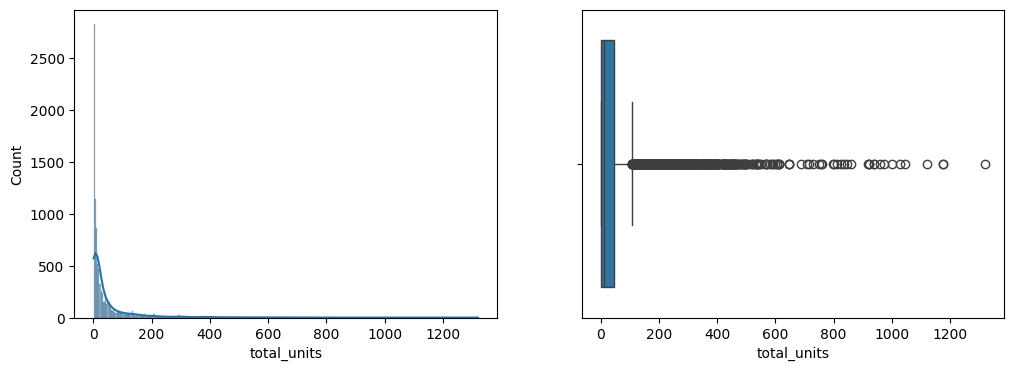

4.594373145026262


In [ ]:
# how the building sizes are spread out. a skew far above 1 means a long tail of very big buildings
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.histplot(df_housing['total_units'], kde=True, ax=ax[0])
sns.boxplot(x=df_housing['total_units'], ax=ax[1])
plt.show()
print(df_housing['total_units'].skew())

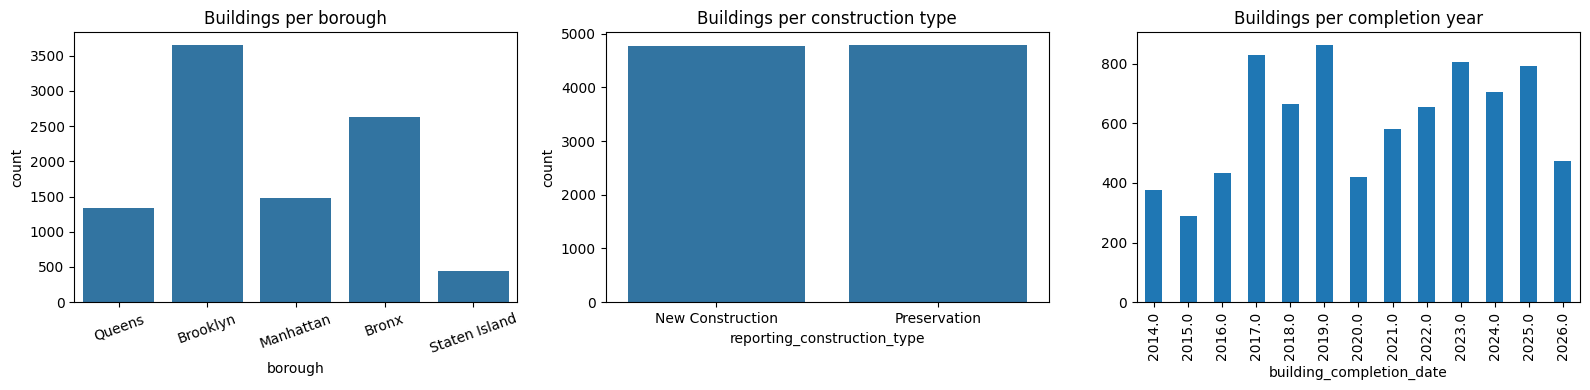

In [ ]:
# initial plots for housing: buildings per borough, per construction type and per completion year
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
sns.countplot(x='borough', data=df_housing, ax=ax[0])
ax[0].set_title('Buildings per borough')
ax[0].tick_params(axis='x', rotation=20)
sns.countplot(x='reporting_construction_type', data=df_housing, ax=ax[1])
ax[1].set_title('Buildings per construction type')
years = pd.to_datetime(df_housing['building_completion_date'], errors='coerce').dt.year
years.value_counts().sort_index().plot(kind='bar', ax=ax[2])
ax[2].set_title('Buildings per completion year')
plt.tight_layout()
plt.show()

# Step 6: EDA of the meters data

These cells inspect meter data types, missing values, duplicates, borough distribution, status/facility categories, meter-hours text, and the projected X/Y fields. In the recorded run, the dataset contained 15,598 rows and 17 columns and had no exact duplicate rows. There were 37 missing status values, 49 missing meter-hours values, and 158 missing facility values. Status and facility values included capitalization variants, which are standardized during cleaning.

The recorded status counts included 12,796 `Active`, 2,763 `Inactive`, two lowercase `active`, and 37 missing values. The recorded facility values included 15,254 `On Street`, 184 `Off Street`, two `ON Street`, and 158 missing values. Parking-facility names are mostly blank because the dataset is dominated by on-street meters; this field is not required for the spatial analysis.

The notebook uses the provided latitude and longitude for spatial analysis. X and Y are projected coordinates and should not be interpreted as latitude and longitude.

The plots below have saved execution results in this notebook. For final reproducibility, run the notebook from a clean kernel against the intended final data snapshot.


In [ ]:
# meters: column types and non-null counts
df_meters.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15598 entries, 0 to 15597
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   objectid               15598 non-null  int64  
 1   meter_number           15598 non-null  int64  
 2   status                 15561 non-null  object 
 3   pay_by_cell_number     15593 non-null  float64
 4   meter_hours            15549 non-null  object 
 5   parking_facility_name  174 non-null    object 
 6   facility               15440 non-null  object 
 7   borough                15598 non-null  object 
 8   on_street              15598 non-null  object 
 9   side_of_street         15594 non-null  object 
 10  from_street            15594 non-null  object 
 11  to_street              15598 non-null  object 
 12  latitude               15598 non-null  float64
 13  longitude              15598 non-null  float64
 14  x                      15598 non-null  float64
 15  y 

In [ ]:
# meters: nulls, duplicates and the categories (look for typos like 'active' vs 'Active')
null_values = df_meters.isnull().sum()
print(null_values[null_values > 0])
print('duplicates:', df_meters.duplicated().sum())
print(df_meters['borough'].value_counts(dropna=False))
print(df_meters['status'].value_counts(dropna=False))
print(df_meters['facility'].value_counts(dropna=False))

status                      37
pay_by_cell_number           5
meter_hours                 49
parking_facility_name    15424
facility                   158
side_of_street               4
from_street                  4
dtype: int64
duplicates: 0
borough
Manhattan        5082
Brooklyn         4254
Queens           4242
Bronx            1681
Staten Island     339
Name: count, dtype: int64
status
Active      12796
Inactive     2763
NaN            37
active          2
Name: count, dtype: int64
facility
On Street     15254
Off Street      184
NaN             158
ON Street         2
Name: count, dtype: int64


In [ ]:
# real values of meter_hours and the coordinates, look before cleaning
print(df_meters['meter_hours'].value_counts().head(20))
# x and y are in feet (not lat/lon), so later we use the latitude and longitude columns instead
df_meters[['x', 'y']].describe()

meter_hours
2HR Pas Mon-Sat 0900-1900                                                        4856
2HR Pas Mon-Sat 0800-1900                                                        2571
2HR Pas Mon-Sat 0830-1900                                                        2228
3HR Com Mon-Fri 0700-1800 / 6HR Pas Mon-Fri 1800-2400 / 6HR Pas Sat 0800-2400     369
3HR Com Mon-Sat 0700-1900                                                         214
2HR Pas Mon-Sat 0800-2200                                                         166
2HR Pas Mon-Sat 0930-1900                                                         162
3HR Com Mon-Fri 0800-1800                                                         158
2HR Pas 0800-1900 Mon-Thur / 4Hr Pas 0800-1900 Fri                                146
2HR Pas Mon-Sat 0830-2200                                                         135
3HR Com Mon-Fri 0700-1900                                                         133
3HR Com Mon-Fri 0800-1900                 

,x,y
count,1.559800e+04,15598.000000
mean,1.002742e+06,203946.497949
std,1.971854e+04,26929.727587
min,9.241857e+05,130074.111293
25%,9.884226e+05,186140.898437
50%,9.974637e+05,207911.917887
75%,1.015472e+06,217455.269782
max,1.067227e+06,270864.386798


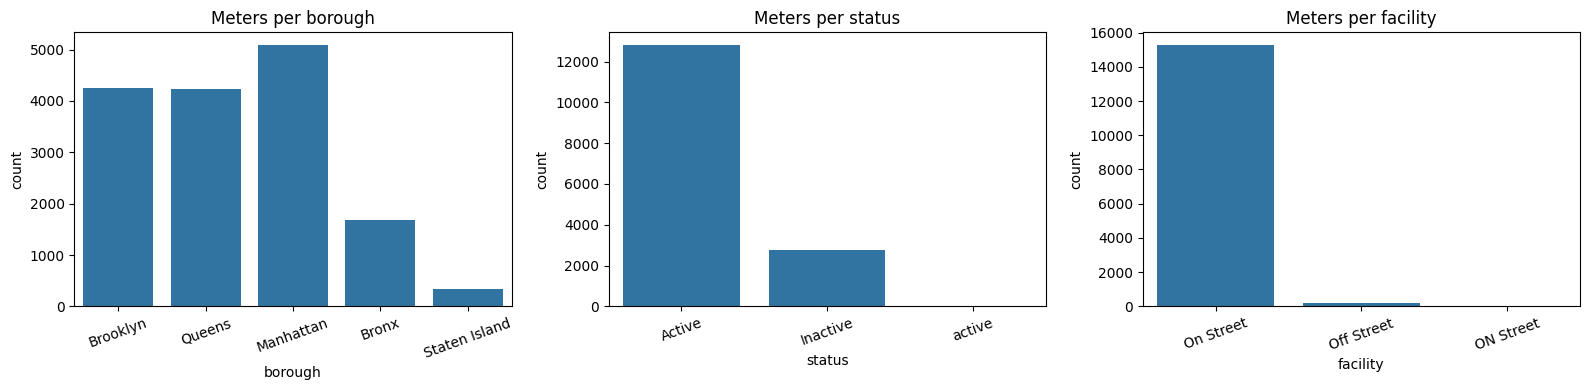

In [ ]:
# initial plots for meters: meters per borough, status and facility (before cleaning, so the typos still show)
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for col, a in zip(['borough', 'status', 'facility'], ax):
    sns.countplot(x=col, data=df_meters, ax=a)
    a.set_title('Meters per ' + col)
    a.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

# Step 7: Clean the housing data

Cleaning decisions implemented below:

- Standardize borough text to uppercase and remove surrounding whitespace so it matches the meter dataset.
- Remove exact duplicate rows. Do not remove records merely because a project may contain multiple building records.
- Parse project and building-completion dates; invalid dates become missing. Derive completion year and project duration, and set negative durations to missing.
- Treat negative unit counts as invalid. The data dictionary does not say what a blank unit count means. We treat a blank as zero units (a building with no 4-bedroom units has nothing to report in that column) and test this assumption in the check cell after the cleaning, by comparing the income-band units with `all_counted_units`.
- Ensure `total_units` is not below `all_counted_units`, and remove rows where total units remain unavailable.
- Prefer internal lot-center coordinates, fall back to the dataset latitude/longitude, and set coordinates outside a broad NYC bounding box to missing.
- Flag confidential projects and unusually large records. Large records are retained because an IQR flag is not proof of an error.
- Create a community-board key that includes borough context, because board numbers can repeat across boroughs.
- Derive unit-composition shares only where the denominator is available.

The code preserves potentially valid large developments and records with missing coordinates rather than silently deleting them.

**Validation note:** the income-band consistency check in the code cell after the cleaning diagnostics should be run before submission; it had no saved execution result in this uploaded notebook.


In [ ]:
# how is community_board written? it is text like BK-05, not a number
print(df_housing['community_board'].dtype)
print(df_housing['community_board'].value_counts(dropna=False).head(10))

object
community_board
BK-05    576
BK-03    552
MN-10    430
BX-12    430
BK-16    365
BK-17    354
BK-01    314
BK-04    298
BX-04    291
QN-12    286
Name: count, dtype: int64


In [ ]:
# cleans the housing table: fixes text, dates, units and coordinates, and makes the columns we need for the questions
def clean_housing(df):
    df = df.copy()

    # same text format as the meters data
    df['borough'] = df['borough'].str.strip().str.upper()

    # exact duplicates only (a building can be in more than one project)
    df = df.drop_duplicates()

    # dates
    for col in ['project_start_date', 'building_completion_date']:
        df[col] = pd.to_datetime(df[col], errors='coerce')
    df['completion_year'] = df['building_completion_date'].dt.year
    df['duration_days'] = (df['building_completion_date'] - df['project_start_date']).dt.days
    df.loc[df['duration_days'] < 0, 'duration_days'] = np.nan
    # the dataset only covers projects after 2014
    df.loc[~df['completion_year'].between(2014, pd.Timestamp.today().year), 'completion_year'] = np.nan

    # unit columns: negative values are errors, blank means zero units
    unit_cols = [c for c in df.columns
                 if c.endswith('_units') and c not in ('all_counted_units', 'total_units')]
    df[unit_cols] = df[unit_cols].where(df[unit_cols] >= 0).fillna(0)

    # total units can not be smaller than the affordable units
    df['total_units'] = df['total_units'].fillna(df['all_counted_units'])
    df.loc[df['total_units'] < df['all_counted_units'], 'total_units'] = df['all_counted_units']
    df = df.dropna(subset=['total_units'])

    # coordinates: lot center first, then the address one, then check the NYC box
    df['lat'] = df['latitude_internal'].fillna(df['latitude'])
    df['lon'] = df['longitude_internal'].fillna(df['longitude'])
    outside = ~(df['lat'].between(40.4, 41.0) & df['lon'].between(-74.3, -73.6))
    df.loc[outside, ['lat', 'lon']] = np.nan

    # confidential projects have no address
    df['is_confidential'] = df['project_name'].str.contains('CONFIDENTIAL', case=False, na=False)

    # community board numbers repeat in every borough, so add the borough
    # cb_raw = the text version (like BK-05), cb_num = the number version (like 5) if there is one
    cb_raw = df['community_board'].astype('string').str.strip().str.upper()
    cb_num = pd.to_numeric(df['community_board'], errors='coerce')
    # numbers get the borough in front, text ones are already complete
    df['cb_id'] = (df['borough'] + '-' + cb_num.astype('Int64').astype('string')).where(cb_num.notna(), cb_raw)

    # shares used in the research questions
    counted = df['all_counted_units'].replace(0, np.nan)
    big_cols = [c for c in ['3_br_units', '4_br_units', '5_br_units', '6_br_units'] if c in df.columns]
    df['share_3br_plus'] = df[big_cols].sum(axis=1) / counted
    income_cols = {
        'share_eli': 'extremely_low_income_units',
        'share_vli': 'very_low_income_units',
        'share_low': 'low_income_units',
        'share_moderate': 'moderate_income_units',
        'share_middle': 'middle_income_units',
        'share_other_income': 'other_income_units'
    }
    for share_col, units_col in income_cols.items():
        df[share_col] = df[units_col] / counted
    df['affordable_share'] = df['all_counted_units'] / df['total_units'].replace(0, np.nan)

    # outliers: IQR rule from Lab 2, we only flag very large buildings
    Q1 = df['total_units'].quantile(0.25)
    Q3 = df['total_units'].quantile(0.75)
    iqr = Q3 - Q1
    df['is_large_building'] = df['total_units'] > Q3 + 1.5 * iqr
    return df

df_housing_clean = clean_housing(df_housing)
print(df_housing.shape, '->', df_housing_clean.shape)

(9551, 41) -> (9551, 56)


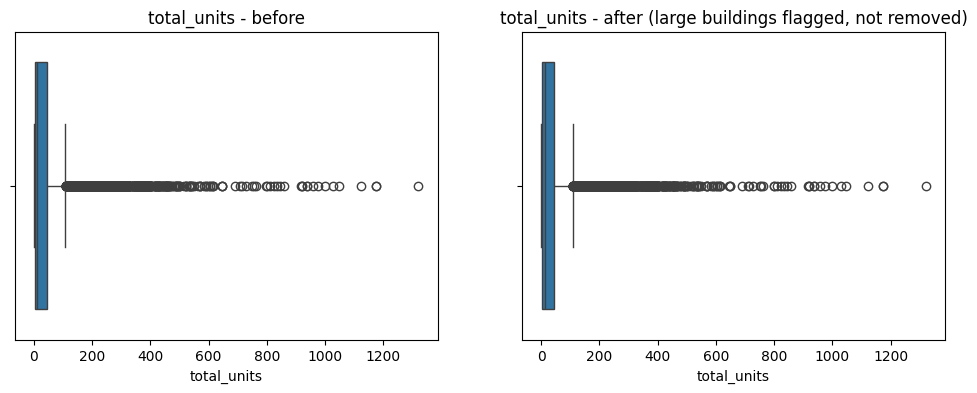

1171 large buildings flagged
1949 confidential rows
lat                1958
lon                1958
completion_year    1666
duration_days      1686
cb_id                 0
dtype: int64


In [ ]:
# check the cleaning: boxplot before vs after, then counts of flagged, confidential and null values
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
sns.boxplot(x=df_housing['total_units'], ax=ax[0])
ax[0].set_title('total_units - before')
sns.boxplot(x=df_housing_clean['total_units'], ax=ax[1])
ax[1].set_title('total_units - after (large buildings flagged, not removed)')
plt.show()

print(df_housing_clean['is_large_building'].sum(), 'large buildings flagged')
print(df_housing_clean['is_confidential'].sum(), 'confidential rows')
print(df_housing_clean[['lat', 'lon', 'completion_year', 'duration_days', 'cb_id']].isnull().sum())

In [ ]:
# check the "blank means zero" assumption: do the income-band units add up to the counted units?
income_cols = ['extremely_low_income_units', 'very_low_income_units', 'low_income_units',
               'moderate_income_units', 'middle_income_units', 'other_income_units']
income_sum = df_housing_clean[income_cols].sum(axis=1)
diff = (income_sum - df_housing_clean['all_counted_units']).abs()
print('income bands add up exactly to all_counted_units:', round((diff == 0).mean() * 100, 1), '% of buildings')
print('differ by more than 1 unit:', round((diff > 1).mean() * 100, 1), '% of buildings')

income bands add up exactly to all_counted_units: 99.7 % of buildings
differ by more than 1 unit: 0.0 % of buildings


# Step 8: Clean the meters data

Cleaning decisions implemented below:

- Standardize borough and status strings; missing status becomes `UNKNOWN` so it is not accidentally counted as active.
- Standardize facility labels and represent missing facility values as `Unknown`.
- Remove exact duplicate rows and then retain one row per `meter_number`.
- Convert the provided latitude/longitude to numeric values and flag coordinates outside the broad NYC bounding box as missing.
- Extract the first hour limit expressed as an `HR` rule from the `meter_hours` text. This is a simplified summary of potentially complex schedules; it does not fully represent multiple weekday/weekend rules in a single meter record.
- Keep longer limits (including 11–18 hours) because the EDA shows that these are actual source values, not necessarily data errors.
- Preserve records with unreadable or non-standard meter-hour descriptions; their parsed numeric time limit remains missing rather than being guessed. This affects meters with no text, meters with the text "Rate NOT Available", and meters whose limit is written in minutes (for example 30 minutes). They are left out of Q10 only.

In [ ]:
# cleans the meters table: fixes text, removes repeated meters, checks the coordinates and reads the time limit
def clean_meters(df):
    df = df.copy()
    df['borough'] = df['borough'].str.strip().str.upper()
    df['status'] = df['status'].str.strip().str.upper().fillna('UNKNOWN')
    df['facility'] = df['facility'].str.strip().str.title().fillna('Unknown')

    df = df.drop_duplicates()
    df = df.drop_duplicates(subset='meter_number')

    df['lat'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['lon'] = pd.to_numeric(df['longitude'], errors='coerce')
    outside = ~(df['lat'].between(40.4, 41.0) & df['lon'].between(-74.3, -73.6))
    df.loc[outside, ['lat', 'lon']] = np.nan

    # first time limit in meter_hours (daytime rule), and "Com" means commercial
    hours = df['meter_hours'].astype('string')
    df['time_limit_hr'] = hours.str.extract(r'(\d+)\s*HR', flags=re.IGNORECASE)[0].astype(float)
    df['commercial_meter'] = hours.str.contains('Com', case=False, na=False)
    # groups for the time limit chart (Q10), the long all-day rules go in the last group
    df['time_limit_group'] = pd.cut(df['time_limit_hr'], bins=[0, 1, 2, 3, 6, 24],
                                    labels=['1 hr', '2 hr', '3 hr', '4-6 hr', '7+ hr (all day)'])
    return df

df_meters_clean = clean_meters(df_meters)
print(df_meters.shape, '->', df_meters_clean.shape)
print(df_meters_clean['status'].value_counts())
print(df_meters_clean['facility'].value_counts())
print(df_meters_clean['time_limit_hr'].value_counts(dropna=False))

(15598, 17) -> (15592, 22)
status
ACTIVE      12793
INACTIVE     2763
UNKNOWN        36
Name: count, dtype: int64
facility
On Street     15253
Off Street      184
Unknown         155
Name: count, dtype: int64
time_limit_hr
2.0     12193
3.0      2414
1.0       403
6.0       151
4.0       135
NaN       106
15.0       89
12.0       73
5.0        16
18.0        7
11.0        3
16.0        2
Name: count, dtype: int64


In [ ]:
# the 11 to 18 hour limits are real all-day rules, not mistakes, so we keep them
print(df_meters_clean[df_meters_clean['time_limit_hr'] >= 10]['meter_hours'].value_counts().head(10))

meter_hours
12HR Pas Mon-Sat 0700-1900     63
15HR Pas Mon-Sat 0800-2200     44
15HR Pas Mon-Sat 0700-2200     28
15HR Pas Mon-Sat 0600-2200      8
15 HR Pas Mon-Sat 0700-2200     8
18HR Pas Mon-Sat 0800-1900      7
12HR Pas Mon-Sat 0600-2200      5
12HR Pas Mon-Sat 0800-2000      5
11 HR Mon-Sat 0600-1800         3
16HR Pas Mon-Sat 0000-2200      2
Name: count, dtype: int64


In [ ]:
# meters whose meter_hours has no number + "HR", so time_limit_hr stayed null
unread = df_meters_clean[df_meters_clean['time_limit_hr'].isna() & df_meters_clean['meter_hours'].notna()]
print(unread['meter_hours'].value_counts().head(10))

# size of each time limit group (used in Q10)
print(df_meters_clean['time_limit_group'].value_counts(dropna=False))

meter_hours
Rate NOT Available - Please request a NEW PERSO, and Once it is Ready, Please Create a New Report    33
30Min Com Mon-Sat 0600-2200                                                                          24
Mon-Fri 0700-1900 / Mon-Fri 1900-2200, Sat 0800-2200                                                  1
Name: count, dtype: int64
time_limit_group
2 hr               12193
3 hr                2414
1 hr                 403
4-6 hr               302
7+ hr (all day)      174
NaN                  106
Name: count, dtype: int64


# Step 9: Integration (the location link)

The datasets do not share a record-level identifier. The housing records have coordinates, and the parking-meter records have coordinates, so the integration uses spatial proximity.

Both datasets are assigned grid-cell indices using approximately 0.0009 degrees of latitude and 0.0012 degrees of longitude per cell (roughly 100 metres per side around NYC). For each target record, the code sums source records in a 7-by-7 cell window when `REACH = 3`. The window is square: its outer edges are roughly 300–400 metres from the target cell, while its corners can be farther away (roughly up to 500 metres). This is not a circular radius and is not a walking-distance calculation.

The building-side metric counts active meters in the surrounding window. The meter-side metric counts affordable-housing records and new-construction records in the surrounding window. Inactive meters are counted separately. Records without usable coordinates retain missing proximity values; they are not incorrectly assigned zero.

The sensitivity check compares smaller and larger windows. In the saved run, 63.9% of coordinate-valid buildings had an active meter within the 2-cell window, 75.7% within the 3-cell window, and 87.8% within the 5-cell window. This demonstrates that the proximity result depends on the selected window size.

Limitations: the grid is an approximation; meters are a snapshot rather than historical observations; multiple meter records may represent nearby meters on the same street; and confidential housing records without coordinates cannot be spatially linked.

In [ ]:
# the location link: cut the map into small squares and count what falls in the squares around each point
# squares of about 100 m: 0.0009 degrees of latitude, 0.0012 degrees of longitude
CELL_LAT = 0.0009
CELL_LON = 0.0012
REACH = 3    # look 3 squares in every direction, so the window edge is 300 to 400 m away

def add_cells(df):
    df = df.copy()
    df['cell_lat'] = np.floor(df['lat'] / CELL_LAT)
    df['cell_lon'] = np.floor(df['lon'] / CELL_LON)
    return df


def neighbour_total(targets, sources, value_col=None):
    # for every row in targets: add up the sources that sit in the window of squares around it
    sources = sources.dropna(subset=['cell_lat', 'cell_lon'])
    if value_col is None:
        per_cell = sources.groupby(['cell_lat', 'cell_lon']).size().reset_index(name='n')
    else:
        per_cell = sources.groupby(['cell_lat', 'cell_lon'])[value_col].sum().reset_index(name='n')

    total = np.zeros(len(targets))
    for dlat in range(-REACH, REACH + 1):
        for dlon in range(-REACH, REACH + 1):
            # move the squares one step, so the merge matches each point with its neighbours
            shifted = per_cell.copy()
            shifted['cell_lat'] = shifted['cell_lat'] - dlat
            shifted['cell_lon'] = shifted['cell_lon'] - dlon
            merged = targets[['cell_lat', 'cell_lon']].merge(
                shifted, on=['cell_lat', 'cell_lon'], how='left')
            total += merged['n'].fillna(0).values

    result = pd.Series(total, index=targets.index)
    return result.where(targets['cell_lat'].notna())   # no coordinates -> unknown, not 0

In [ ]:
# use the function in both directions: meters around each building, and buildings around each meter
buildings = add_cells(df_housing_clean)
meters = add_cells(df_meters_clean)

# helper columns so we can add up the time limits
meters['has_limit'] = meters['time_limit_hr'].notna().astype(int)
meters['limit_filled'] = meters['time_limit_hr'].fillna(0)

# only active meters count as parking, inactive ones are kept in a separate group
active = meters[meters['status'] == 'ACTIVE']
inactive = meters[meters['status'] == 'INACTIVE']
new_buildings = buildings[buildings['reporting_construction_type'].str.contains('new', case=False, na=False)]

# building side: what is around each affordable building
buildings['meters_nearby'] = neighbour_total(buildings, active)
buildings['inactive_nearby'] = neighbour_total(buildings, inactive)
limit_sum = neighbour_total(buildings, active, 'limit_filled')
limit_count = neighbour_total(buildings, active, 'has_limit')
buildings['avg_time_limit_nearby'] = limit_sum / limit_count.replace(0, np.nan)
buildings['near_meter'] = (buildings['meters_nearby'] > 0).astype(float).where(
    buildings['meters_nearby'].notna())

# meter side: how much affordable housing is around each meter
meters['buildings_nearby'] = neighbour_total(meters, buildings)
meters['new_buildings_nearby'] = neighbour_total(meters, new_buildings)
meters['near_housing'] = (meters['buildings_nearby'] > 0).astype(float).where(
    meters['buildings_nearby'].notna())
meters['near_new_housing'] = (meters['new_buildings_nearby'] > 0).astype(float).where(
    meters['new_buildings_nearby'].notna())

print(buildings['meters_nearby'].describe())
print('buildings near an active meter:', round(buildings['near_meter'].mean() * 100, 1), '%')
print('meters near affordable housing:', round(meters['near_housing'].mean() * 100, 1), '%')

count    7593.000000
mean       13.265113
std        16.595484
min         0.000000
25%         1.000000
50%         9.000000
75%        19.000000
max       151.000000
Name: meters_nearby, dtype: float64
buildings near an active meter: 75.7 %
meters near affordable housing: 77.2 %


In [ ]:
# does the result depend on the window size? try 2, 3 and 5 squares
for reach in [2, 3, 5]:
    REACH = reach
    test = neighbour_total(buildings, active)
    print(reach, 'squares ->', round((test.dropna() > 0).mean() * 100, 1), '% of buildings near a meter')
REACH = 3   # back to the value we use

2 squares -> 63.9 % of buildings near a meter
3 squares -> 75.7 % of buildings near a meter
5 squares -> 87.8 % of buildings near a meter


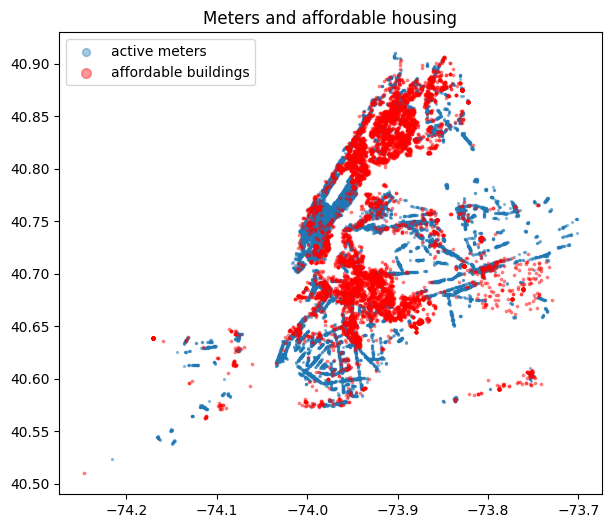

In [ ]:
# quick map to check both datasets are in the right place (blue = meters, red = buildings)
# validation plot: both datasets on one map
plt.figure(figsize=(7, 6))
plt.scatter(active['lon'], active['lat'], s=2, alpha=0.4, label='active meters')
plt.scatter(buildings['lon'], buildings['lat'], s=3, alpha=0.4, color='red', label='affordable buildings')
plt.legend(markerscale=4)
plt.title('Meters and affordable housing')
plt.show()

# Step 10: Aggregation

The notebook creates summaries at three levels, each tied to a research question:

- **Borough:** combines active-meter counts with affordable-unit totals to calculate active meters per 1,000 affordable units (Q1). The ratio divides all active meters in a borough by that borough's affordable units, so it describes the borough as a whole and not only the meters near the housing. An outer join preserves boroughs present in either summary; the saved EDA showed that the borough labels match.
- **Community board:** compares newly constructed affordable units with average nearby active-meter counts (Q6). The community-board key includes borough context to avoid combining identically numbered boards from different boroughs.
- **Completion year:** summarizes affordable housing records and the share near an active meter (Q2). Records without a usable completion year are excluded from this year-level summary and remain in the record-level dataset.

Aggregation avoids attempting to match individual housing and meter records as if they described the same entity. The spatial proximity measures are computed first, then summarized at interpretable geographic or temporal levels.

In [ ]:
# summary tables: by borough (Q1), by community board (Q6) and by completion year (Q2)
housing_by_borough = buildings.groupby('borough').agg(
    buildings=('borough', 'size'),
    affordable_units=('all_counted_units', 'sum'),
    share_near_meter=('near_meter', 'mean'),
    avg_meters_nearby=('meters_nearby', 'mean')).reset_index()

meters_by_borough = meters.groupby('borough').agg(
    meters_all=('borough', 'size'),
    meters_active=('status', lambda s: (s == 'ACTIVE').sum()),
    meters_inactive=('status', lambda s: (s == 'INACTIVE').sum())).reset_index()

# borough names must match in both, otherwise the merge creates fake rows
print(set(housing_by_borough['borough']) ^ set(meters_by_borough['borough']))

borough_summary = pd.merge(housing_by_borough, meters_by_borough, on='borough', how='outer')

# Q6 is specifically about new construction, so do not mix preservation records into this table.
new_buildings = buildings[
    buildings['reporting_construction_type'].str.contains('new', case=False, na=False)
].copy()

cb_summary = (new_buildings.dropna(subset=['cb_id']).groupby('cb_id')
              .agg(borough=('borough', 'first'),
                   new_buildings=('borough', 'size'),
                   new_affordable_units=('all_counted_units', 'sum'),
                   avg_meters_nearby=('meters_nearby', 'mean'),
                   share_near_meter=('near_meter', 'mean'))
              .reset_index())

year_summary = (buildings.dropna(subset=['completion_year']).groupby('completion_year')
                .agg(buildings=('borough', 'size'),
                     affordable_units=('all_counted_units', 'sum'),
                     share_near_meter=('near_meter', 'mean'))
                .reset_index())
year_summary['completion_year'] = year_summary['completion_year'].astype(int)

print(borough_summary)
print(cb_summary.shape, year_summary.shape)

set()
         borough  buildings  affordable_units  share_near_meter  \
0          BRONX       2630          106661.0          0.812700   
1       BROOKLYN       3649           90784.0          0.656321   
2      MANHATTAN       1485           74338.0          0.971408   
3         QUEENS       1342           42952.0          0.713921   
4  STATEN ISLAND        445            6211.0          0.155039   

   avg_meters_nearby  meters_all  meters_active  meters_inactive  
0          10.344906        1680           1413              263  
1           9.571937        4254           3672              580  
2          25.859900        5078           3960             1105  
3          15.329502        4241           3470              757  
4           2.248062         339            278               58  
(59, 6) (13, 4)


# Step 11: Post-integration cleaning (required)

After the borough-level outer join, missing meter or housing counts are filled with zero only for the count columns, because absence from one side of the summary means no matching borough summary row. Proximity measures for individual records without coordinates remain missing, not zero.

The final tables remove redundant source-coordinate and helper columns that are not needed by the website. Date, year, identifier, and postcode fields are converted to consistent types. Final duplicate checks are applied before export. The cells below report remaining missing values and final shapes so the cleaning can be validated after rerunning.

In [ ]:
# after the join: boroughs with no meters row get 0, then meters per 1000 affordable units for Q1
# 1) new missing values from the join
count_cols = ['meters_all', 'meters_active', 'meters_inactive', 'buildings', 'affordable_units']
borough_summary[count_cols] = borough_summary[count_cols].fillna(0)
borough_summary['meters_per_1000_units'] = (
    borough_summary['meters_active'] / (borough_summary['affordable_units'] / 1000))
borough_summary = borough_summary.replace([np.inf, -np.inf], np.nan)
print(borough_summary.isnull().sum())

borough                  0
buildings                0
affordable_units         0
share_near_meter         0
avg_meters_nearby        0
meters_all               0
meters_active            0
meters_inactive          0
meters_per_1000_units    0
dtype: int64


In [ ]:
# drop the columns we don't need and fix the data types
# 2) redundant columns
# Keep the cleaned lat/lon fields for the website map; remove only the raw source coordinates.
drop_cols = ['latitude', 'longitude', 'latitude_internal', 'longitude_internal',
             'number', 'street', 'bbl', 'bin', 'council_district', 'cell_lat', 'cell_lon']
buildings_final = buildings.drop(columns=[c for c in drop_cols if c in buildings.columns])
# Keep cleaned lat/lon for mapping; remove raw/projected coordinate fields and helper columns.
meters_final = meters.drop(columns=[c for c in ['latitude', 'longitude', 'x', 'y', 'location',
                                                 'cell_lat', 'cell_lon', 'limit_filled', 'has_limit']
                                    if c in meters.columns])

# 3) data types
buildings_final['completion_year'] = buildings_final['completion_year'].astype('Int64')
# these two were read as text / decimals
buildings_final['project_completion_date'] = pd.to_datetime(buildings_final['project_completion_date'], errors='coerce')
buildings_final['building_id'] = pd.to_numeric(buildings_final['building_id'], errors='coerce').astype('Int64')
buildings_final['postcode'] = (pd.to_numeric(buildings_final['postcode'], errors='coerce')
                               .astype('Int64').astype('string').str.zfill(5))
buildings_final = buildings_final.drop_duplicates()
meters_final = meters_final.drop_duplicates()

print(buildings_final.shape, meters_final.shape)
print(buildings_final.dtypes)
print(buildings_final[['meters_nearby', 'completion_year', 'cb_id']].isnull().sum())

(9551, 51) (15592, 21)
project_id                                   int64
project_name                                object
project_start_date                  datetime64[ns]
project_completion_date             datetime64[ns]
building_id                                  Int64
borough                                     object
postcode                            string[python]
community_board                             object
census_tract                               float64
nta_neighborhood_tabulation_area            object
building_completion_date            datetime64[ns]
reporting_construction_type                 object
extended_affordability_only                 object
prevailing_wage_status                      object
extremely_low_income_units                 float64
very_low_income_units                      float64
low_income_units                           float64
moderate_income_units                      float64
middle_income_units                        float64
other_in

# Step 12: Save the integrated data

The notebook exports the record-level integrated housing and meter tables and the borough, community-board, and completion-year summaries as CSV files in the `data/` directory. These files are the input of the interactive website (see the repository README for the website, its deployment link and setup steps).

**Website handoff note:** the exported integrated tables retain the cleaned `lat` and `lon` fields so the website can build a geographic visualization. The notebook does not itself contain the separate Dash/React/Flask website, deployment, GitHub repository, or README deliverables required by the milestone.


In [ ]:
# save the final tables, the website will load these files
os.makedirs('data', exist_ok=True)
buildings_final.to_csv('data/buildings_integrated.csv', index=False)
meters_final.to_csv('data/meters_integrated.csv', index=False)
borough_summary.to_csv('data/borough_summary.csv', index=False)
cb_summary.to_csv('data/community_board_summary.csv', index=False)
year_summary.to_csv('data/year_summary.csv', index=False)
print(os.listdir('data'))

['year_summary.csv', 'buildings_integrated.csv', 'borough_summary.csv', 'community_board_summary.csv', 'meters_integrated.csv']


# Step 13: Research questions and interactive visualizations

The following cell creates one interactive Plotly chart for each of the 12 research questions. Plotly charts support hover details and interactive zoom/pan where applicable. Each chart is generated from the cleaned/integrated tables created above.

**How to interpret:** use the chart title and axis labels to understand the comparison. These charts are descriptive. They do not establish causation, and their interpretation is subject to the spatial-window, snapshot-date, missing-coordinate, and dataset-definition limitations described earlier.

The team allocation in the introduction assigns two questions/charts to each of the six members.

**Notes on reading the charts:**
- Q4, Q5 and Q11 use shares of `all_counted_units`, so buildings where that number is missing or zero have no share and are not plotted.
- In Q5, `other_income_units` are units reserved for building superintendents (data dictionary), so that panel is not an income band in the same sense as the other five.
- Q1 is a borough-wide ratio (see Step 10), and Q2 compares buildings completed in each year with the meters that exist today.
- Q7 shows locations only. Many points overlap in dense areas, so the map shows where both exist but not how many.

In [ ]:
# Interactive visualizations for Q1-Q12
# The charts are generated from the integrated tables created above.

# Q1: Active meters per 1,000 affordable units by borough.
q1 = borough_summary.dropna(subset=['meters_per_1000_units'])
fig_q1 = px.bar(
    q1, x='borough', y='meters_per_1000_units',
    hover_data=['meters_active', 'affordable_units'],
    title='Q1. Active parking meters per 1,000 affordable housing units',
    labels={'borough': 'Borough', 'meters_per_1000_units': 'Active meters per 1,000 affordable units'}
)
fig_q1.show()

# Q2: Share of housing records near an active meter by completion year.
q2 = year_summary.dropna(subset=['completion_year', 'share_near_meter']).sort_values('completion_year')
fig_q2 = px.line(
    q2, x='completion_year', y='share_near_meter', markers=True,
    hover_data=['buildings', 'affordable_units'],
    title='Q2. Share of affordable housing records near an active meter by completion year',
    labels={'completion_year': 'Building completion year', 'share_near_meter': 'Share near an active meter'}
)
fig_q2.update_yaxes(tickformat='.0%')
fig_q2.show()

# Q3: Compare nearby active-meter counts for new construction and preservation.
q3 = buildings.dropna(subset=['reporting_construction_type', 'meters_nearby'])
fig_q3 = px.box(
    q3, x='reporting_construction_type', y='meters_nearby', points='outliers',
    title='Q3. Nearby active meters: new construction vs. preservation',
    labels={'reporting_construction_type': 'Construction type', 'meters_nearby': 'Active meters in proximity window'}
)
fig_q3.show()

# Q4: Bedroom composition and nearby active-meter counts.
q4 = buildings.dropna(subset=['share_3br_plus', 'meters_nearby'])
fig_q4 = px.scatter(
    q4, x='share_3br_plus', y='meters_nearby', color='borough',
    hover_data=['total_units', 'all_counted_units'],
    title='Q4. Three-bedroom-plus unit share vs. nearby active meters',
    labels={'share_3br_plus': 'Share of counted units with 3+ bedrooms',
            'meters_nearby': 'Nearby active meters'}
)
fig_q4.update_xaxes(tickformat='.0%')
fig_q4.show()

# Q5: Compare the relationship for each reported income band.
income_share_cols = ['share_eli', 'share_vli', 'share_low', 'share_moderate', 'share_middle', 'share_other_income']
q5 = buildings[['meters_nearby'] + income_share_cols].melt(
    id_vars='meters_nearby', var_name='income_band', value_name='unit_share'
).dropna(subset=['meters_nearby', 'unit_share'])
fig_q5 = px.scatter(
    q5, x='unit_share', y='meters_nearby', facet_col='income_band', facet_col_wrap=3,
    title='Q5. Affordable-housing income-band share vs. nearby active meters',
    labels={'unit_share': 'Income-band units / all counted units',
            'meters_nearby': 'Nearby active meters', 'income_band': 'Income band'}
)
fig_q5.update_xaxes(tickformat='.0%')
fig_q5.show()

# Q6: New affordable units by community board against average nearby active meters.
q6 = cb_summary.dropna(subset=['new_affordable_units', 'avg_meters_nearby'])
fig_q6 = px.scatter(
    q6, x='new_affordable_units', y='avg_meters_nearby', color='borough',
    hover_data=['cb_id', 'new_buildings', 'share_near_meter'],
    title='Q6. New affordable units and nearby active meters by community board',
    labels={'new_affordable_units': 'New affordable units',
            'avg_meters_nearby': 'Average nearby active meters', 'borough': 'Borough'}
)
fig_q6.show()

# Q7: Geographic overlap of housing records and active parking meters.
housing_map = buildings.dropna(subset=['lat', 'lon'])[['lat', 'lon']].copy()
housing_map['location_type'] = 'Affordable housing'
meter_map = active.dropna(subset=['lat', 'lon'])[['lat', 'lon']].copy()
meter_map['location_type'] = 'Active parking meter'
map_data = pd.concat([housing_map, meter_map], ignore_index=True)
fig_q7 = px.scatter_geo(
    map_data, lat='lat', lon='lon', color='location_type',
    scope='north america',
    center={'lat': 40.72, 'lon': -73.95},
    projection='mercator',
    title='Q7. Geographic distribution of affordable housing and active parking meters',
    labels={'lat': 'Latitude', 'lon': 'Longitude', 'location_type': 'Location type'}
)
fig_q7.update_geos(
    lataxis_range=[40.45, 40.95], lonaxis_range=[-74.30, -73.65],
    showcountries=False, showland=True
)
fig_q7.show()

# Q8: Status distribution for meters near and not near new affordable housing.
q8_base = meters.dropna(subset=['near_new_housing', 'status']).copy()
q8_base['new_housing_proximity'] = q8_base['near_new_housing'].map(
    {0.0: 'No new housing nearby', 1.0: 'New housing nearby'}
)
q8 = (q8_base.groupby(['new_housing_proximity', 'status']).size()
      .reset_index(name='meter_count'))
q8['share_within_group'] = q8.groupby('new_housing_proximity')['meter_count'].transform(
    lambda values: values / values.sum()
)
fig_q8 = px.bar(
    q8, x='new_housing_proximity', y='share_within_group', color='status',
    barmode='stack', hover_data=['meter_count'],
    title='Q8. Meter status (including unknown) by proximity to new affordable housing',
    labels={'new_housing_proximity': 'New affordable housing proximity',
            'share_within_group': 'Share of meters', 'status': 'Meter status'}
)
fig_q8.update_yaxes(tickformat='.0%')
fig_q8.show()

# Q9: Building size vs. nearby active meters.
q9 = buildings.dropna(subset=['total_units', 'meters_nearby'])
fig_q9 = px.scatter(
    q9, x='total_units', y='meters_nearby', color='borough',
    hover_data=['project_id', 'reporting_construction_type'],
    title='Q9. Total housing units vs. nearby active meters',
    labels={'total_units': 'Total units in housing record', 'meters_nearby': 'Nearby active meters'}
)
fig_q9.show()

# Q10: Time-limit category for meters near housing and meters not near housing.
q10 = meters.dropna(subset=['time_limit_group', 'near_housing']).copy()
q10['housing_proximity'] = q10['near_housing'].map(
    {0.0: 'No affordable housing nearby', 1.0: 'Affordable housing nearby'}
)
q10_summary = (q10.groupby(['housing_proximity', 'time_limit_group'], observed=False)
               .size().reset_index(name='meter_count'))
fig_q10 = px.bar(
    q10_summary, x='time_limit_group', y='meter_count', color='housing_proximity',
    barmode='group',
    title='Q10. Meter time-limit categories by proximity to affordable housing',
    labels={'time_limit_group': 'Parsed time-limit group', 'meter_count': 'Number of meters',
            'housing_proximity': 'Housing proximity'}
)
fig_q10.show()

# Q11: Affordable share vs. nearby active meters.
q11 = buildings.dropna(subset=['affordable_share', 'meters_nearby'])
fig_q11 = px.scatter(
    q11, x='affordable_share', y='meters_nearby', color='borough',
    hover_data=['total_units', 'all_counted_units'],
    title='Q11. Affordable-unit share vs. nearby active meters',
    labels={'affordable_share': 'Counted affordable units / total units',
            'meters_nearby': 'Nearby active meters'}
)
fig_q11.update_xaxes(tickformat='.0%')
fig_q11.show()

# Q12: Project duration for records with and without a nearby active meter.
q12 = buildings.dropna(subset=['duration_days', 'near_meter']).copy()
q12['meter_proximity'] = q12['near_meter'].map(
    {0.0: 'No active meter nearby', 1.0: 'Active meter nearby'}
)
fig_q12 = px.box(
    q12, x='meter_proximity', y='duration_days', points='outliers',
    title='Q12. Project duration with and without a nearby active meter',
    labels={'meter_proximity': 'Active-meter proximity', 'duration_days': 'Project duration (days)'}
)
fig_q12.show()


# Step 14: Findings, limits and impact

## Main question
We investigated how the locations of affordable-housing records relate geographically to the current locations and status of NYC parking meters. This matters because housing and curbside infrastructure are planned by different city systems, but residents experience them in the same neighborhoods.

## Findings from the recorded notebook run
- **Nearby active meters:** 75.7% of housing records with usable coordinates had at least one active meter in the selected 7-by-7 grid window. This is a proximity indicator, not a measure of parking capacity or guaranteed access.
- **Nearby affordable housing:** 77.2% of meter records with usable coordinates had at least one affordable-housing record in the same proximity window.
- **Borough differences:** the borough summary recorded an average of about 25.9 nearby active meters per housing record in Manhattan, compared with about 2.2 in Staten Island. These differences are descriptive and are affected by density and the chosen grid window.
- **Window sensitivity:** the share of coordinate-valid housing records classified as near an active meter rose from 63.9% with a 2-cell reach, to 75.7% with a 3-cell reach, and 87.8% with a 5-cell reach. The result therefore depends materially on the proximity definition.

## Limitations
- The housing file contains project/building records; a row is not necessarily a unique physical building.
- Parking-meter locations and status are a current snapshot, not historical observations matched to each project's completion date.
- A meter is not the same as a parking space, and this analysis does not measure total parking supply, occupancy, price, or parking demand.
- The grid is a square-window approximation rather than a circular distance or walking/road-network distance. Its corners extend farther than its sides.
- 1,958 of 9,551 housing records (about 20.5%) have no usable coordinates after cleaning, so they cannot receive a proximity measure. This is not assumed to mean all such records are confidential.
- The proximity measures count nearby records; dense areas may have many meters or housing records close together. Results show association, not causation.
- The income-band blank-as-zero assumption is a working assumption that should be reviewed against the data dictionary and the validation cell's output.

## Potential impact
City planners and housing advocates could use these results as an initial screening view to identify boroughs and community boards for closer investigation. Transportation and curb-management teams could combine this analysis with parking occupancy, curb regulations, transit access, and historical meter records before making policy decisions. The notebook alone does not justify adding or removing meters or changing housing policy.

## Final interpretation
The strongest supported conclusion is that affordable-housing records and active parking meters frequently occur within the selected geographic window, but the measured level of overlap changes substantially with the window size. The analysis is useful for exploratory screening, not for causal claims or operational decisions without additional data.
